In [31]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn.datasets 
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn import metrics
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor

In [32]:
df1 = pd.read_csv('../data/Boston House Price Data.csv')
df1

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,PRICE
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0.0,0.573,6.593,69.1,2.4786,1.0,273.0,21.0,391.99,9.67,22.4
502,0.04527,0.0,11.93,0.0,0.573,6.120,76.7,2.2875,1.0,273.0,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0.0,0.573,6.976,91.0,2.1675,1.0,273.0,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0.0,0.573,6.794,89.3,2.3889,1.0,273.0,21.0,393.45,6.48,22.0


## Pre processing data

In [33]:
X = df1.drop(['PRICE'], axis=1)
Y = df1['PRICE']

Train Test split

In [34]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)

In [35]:
print(X.shape, X_train.shape, X_test.shape)

(506, 13) (404, 13) (102, 13)


## Model Training

### XGBoost

In [36]:
xgbmodel = XGBRegressor()

In [37]:
# training the model using X_train
xgbmodel.fit(X_train, Y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


Evaluation

In [38]:
# accuracy for prediction on training data
trainingData_pred = xgbmodel.predict(X_train)

In [39]:
print(trainingData_pred)

[23.141842  20.983284  20.103428  34.69142   13.91575   13.498004
 21.998333  15.193665  10.903449  22.686766  13.80649    5.607422
 29.808262  50.005924  34.894993  20.60206   23.386408  19.204628
 32.70533   19.60305   26.996607   8.402646  45.998173  21.70041
 27.0927    19.390596  19.298737  24.807426  22.604942  31.701603
 18.530865   8.703727  17.404043  23.697786  13.300571  10.502583
 12.673761  24.997698  19.699127  14.902126  24.201878  24.992424
 14.909092  17.014936  15.591565  12.708229  24.512085  15.005392
 50.00175   17.518436  21.200298  32.01788   15.605521  22.894588
 19.31703   18.732553  23.298687  37.198833  30.092299  33.09997
 20.998034  49.99952   13.399705   5.0028057 16.498236   8.407585
 28.684132  19.504543  20.595694  45.407364  39.794533  33.402294
 19.80457   33.404335  25.296593  49.997654  12.51744   17.431204
 18.602709  22.599882  50.00823   23.817463  23.29894   23.096525
 41.701786  16.114292  31.620422  36.09577    7.0017447 20.381474
 20.00001   

In [51]:
# Compare X_train pred value vs Y_train
# R squared error
score_r = metrics.r2_score(Y_train, trainingData_pred)

# Mean absolute error
score_mae = metrics.mean_absolute_error(Y_train, trainingData_pred)

print("R squared error : ", score_r)
print("Mean absolute error : ", score_mae)

R squared error :  0.9999984582775392
Mean absolute error :  0.008061628530521298


In [41]:
# accuracy on test data
testData_pred = xgbmodel.predict(X_test)

In [52]:
# Compare X_test pred value vs Y_test
# R squared error
score_rt = metrics.r2_score(Y_test, testData_pred)

# Mean absolute error
score_maet = metrics.mean_absolute_error(Y_test, testData_pred)

# Root mean squared error
rmse = np.sqrt(metrics.mean_squared_error(Y_test, testData_pred))

print("R squared error : ", score_rt)
print("Mean absolute error : ", score_maet)
print("Root mean squared error : ", rmse)

R squared error :  0.8771087539079264
Mean absolute error :  2.248779092115514
Root mean squared error :  3.2064064855532592


### Random Forest Regressor

In [43]:
rfmodel = RandomForestRegressor(n_estimators=300, random_state=2, n_jobs=-1)
rfmodel.fit(X_train, Y_train)

rf_pred = rfmodel.predict(X_test)
print("R squared :", metrics.r2_score(Y_test, rf_pred))
print("MAE       :", metrics.mean_absolute_error(Y_test, rf_pred))
print("RMSE      :", np.sqrt(metrics.mean_squared_error(Y_test, rf_pred)))

R squared : 0.8840041354281318
MAE       : 2.1701045751633954
RMSE      : 3.115152825522632


## Model Comparison

### Actual Prices vs Predicted Prices (Test Set)

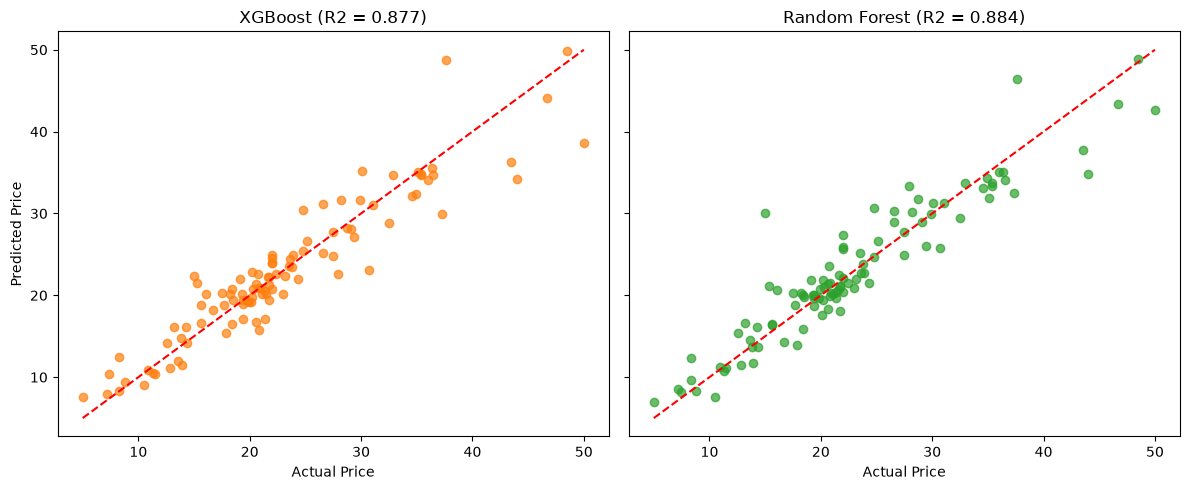

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
lims = [Y_test.min(), Y_test.max()]
for ax, (name, pred, color) in zip(axes, [("XGBoost", testData_pred, "tab:orange"), ("Random Forest", rf_pred, "tab:green")]):
    ax.scatter(Y_test, pred, color=color, alpha=0.7)
    ax.plot(lims, lims, "r--")
    ax.set_title(f"{name} (R2 = {metrics.r2_score(Y_test, pred):.3f})")
    ax.set_xlabel("Actual Price")
axes[0].set_ylabel("Predicted Price")
plt.tight_layout()
plt.show()

### Performance Metrics

      XGBoost  Random Forest
R2      0.877          0.884
MAE     2.249          2.170
RMSE    3.206          3.115


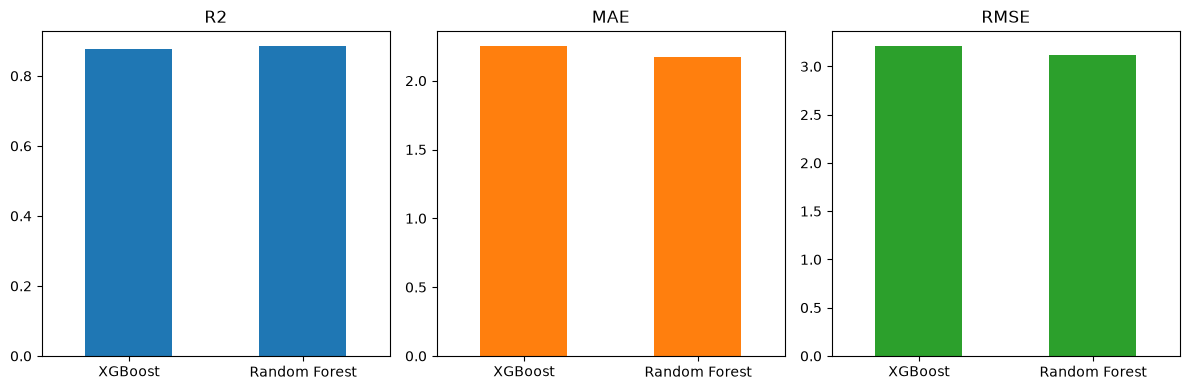

In [48]:
results = pd.DataFrame(
    {
        "XGBoost": [
            metrics.r2_score(Y_test, testData_pred),
            metrics.mean_absolute_error(Y_test, testData_pred),
            np.sqrt(metrics.mean_squared_error(Y_test, testData_pred)),
        ],
        "Random Forest": [
            metrics.r2_score(Y_test, rf_pred),
            metrics.mean_absolute_error(Y_test, rf_pred),
            np.sqrt(metrics.mean_squared_error(Y_test, rf_pred)),
        ],
    },
    index=["R2", "MAE", "RMSE"],
)
print(results.round(3))
results.T.plot(kind="bar", subplots=True, layout=(1, 3), figsize=(12, 4), legend=False, rot=0)
plt.tight_layout()
plt.show()

### Feature Importance

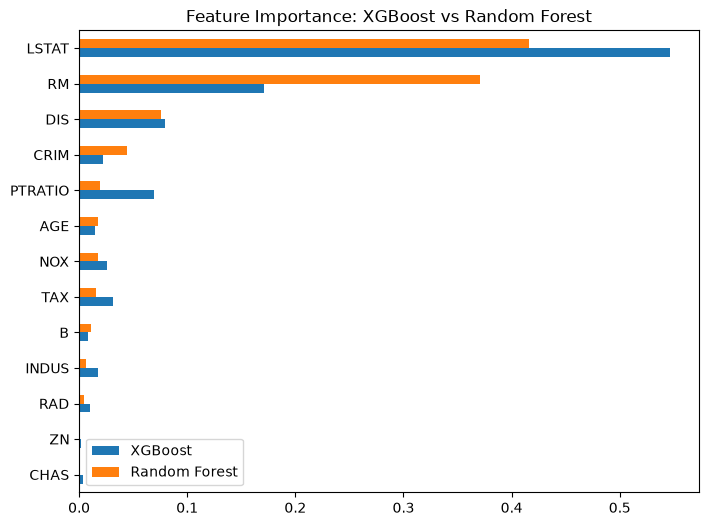

In [49]:
importances = pd.DataFrame(
    {"XGBoost": xgbmodel.feature_importances_, "Random Forest": rfmodel.feature_importances_},
    index=X.columns,
).sort_values("Random Forest")
importances.plot(kind="barh", figsize=(8, 6))
plt.title("Feature Importance: XGBoost vs Random Forest")
plt.show()

## Cross Validation

XGBoost [0.877 0.87  0.907 0.767 0.892] 0.862
Random Forest [0.892 0.907 0.884 0.772 0.886] 0.868


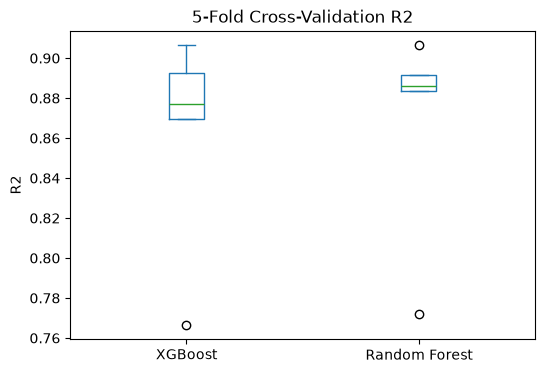

In [46]:
from sklearn.model_selection import KFold, cross_val_score

kf = KFold(n_splits=5, shuffle=True, random_state=2)
cv_results = {}
for name, model in [("XGBoost", XGBRegressor()), ("Random Forest", RandomForestRegressor(n_estimators=300, random_state=2, n_jobs=-1))]:
    cv_results[name] = cross_val_score(model, X, Y, cv=kf, scoring="r2")
    print(name, cv_results[name].round(3), round(cv_results[name].mean(), 3))

pd.DataFrame(cv_results).plot(kind="box", figsize=(6, 4))
plt.ylabel("R2")
plt.title("5-Fold Cross-Validation R2")
plt.show()

## Saving the models

In [29]:
os.makedirs("../models", exist_ok=True)
joblib.dump(xgbmodel, "../models/xgb_model.joblib")
joblib.dump(rfmodel, "../models/rf_model.joblib")

['../models/rf_model.joblib']